# Practical 3 — Bank Customer Churn Prediction using a Neural Network

**Subject:** Machine Learning (410242)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Given a bank customer, build a neural-network-based classifier that predicts
whether the customer will leave the bank in the next six months.

## 2. Dataset

**Churn Modelling Dataset** — Kaggle:  
<https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling>

The dataset contains 10,000 customers and 14 columns:

| Column | Meaning |
|---|---|
| `RowNumber`, `CustomerId`, `Surname` | Identifiers (dropped) |
| `CreditScore` | Customer's credit score |
| `Geography` | Country (France, Germany, Spain) |
| `Gender` | Male / Female |
| `Age` | Customer's age |
| `Tenure` | Years as a bank customer |
| `Balance` | Account balance |
| `NumOfProducts` | Number of bank products used |
| `HasCrCard` | Has a credit card (0/1) |
| `IsActiveMember` | Active member (0/1) |
| `EstimatedSalary` | Estimated salary |
| `Exited` | **Target:** 1 = left the bank, 0 = stayed |

The CSV is stored as `data/Churn_Modelling.csv.gz`.

## 3. Objectives

- Read and explore a real tabular dataset.
- Separate features and target, encode categorical variables and scale
  numerical features.
- Build a feed-forward neural network classifier.
- Identify weaknesses of the baseline model and implement improvements.
- Report accuracy, confusion matrix, precision, recall, F1 and ROC-AUC.

## 4. Theory

### 4.1 Artificial neuron

A neuron computes a weighted sum of its inputs and applies an activation
function:

$$z=\sum_{i=1}^{n}w_i x_i+b,\qquad a=\phi(z).$$

Common activations:

- **ReLU:** $\phi(z)=\max(0,z)$ — cheap and avoids vanishing gradients.
- **Sigmoid:** $\phi(z)=1/(1+e^{-z})$ — used in the output layer for a
  probability.

### 4.2 Feed-forward network

A multilayer perceptron (MLP) stacks layers:

$$h^{(1)}=\phi(W^{(1)}x+b^{(1)}),\qquad
h^{(2)}=\phi(W^{(2)}h^{(1)}+b^{(2)}),\qquad
\hat{y}=\sigma(W^{(3)}h^{(2)}+b^{(3)}).$$

For binary classification, the output $\hat{y}\in(0,1)$ is interpreted as
$P(y=1\mid x)$. The loss is binary cross-entropy:

$$L=-\frac{1}{n}\sum_{i=1}^{n}\bigl[y_i\log\hat{y}_i+
(1-y_i)\log(1-\hat{y}_i)\bigr].$$

### 4.3 Back-propagation and Adam

Back-propagation computes the gradient of the loss with respect to every
weight using the chain rule. The weights are updated in the opposite
direction:

$$W\leftarrow W-\eta\frac{\partial L}{\partial W}.$$

**Adam** adapts the learning rate per parameter using estimates of the first
and second moments of the gradients, which usually converges faster than plain
gradient descent.

### 4.4 Class imbalance

About 20% of customers in this dataset churn. A network trained with ordinary
cross-entropy can achieve high accuracy by predicting "stayed" for almost
everyone, while missing most churners. Two common remedies are:

- **class weights** — give the minority class a larger weight in the loss,
- **threshold tuning** — lower the decision threshold below 0.5.

We use class weights and report precision/recall/F1, not only accuracy.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("ML/data")

In [2]:
df = pd.read_csv(DATA_DIR / "Churn_Modelling.csv.gz")
print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [4]:
print("Missing values:")
print(df.isna().sum().to_string())
print("\nTarget distribution:")
print(df["Exited"].value_counts().rename({0: "Stayed (0)", 1: "Exited (1)"}))
print("Churn rate:", f"{df['Exited'].mean():.2%}")

Missing values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0

Target distribution:
Exited
Stayed (0)    7963
Exited (1)    2037
Name: count, dtype: int64
Churn rate: 20.37%


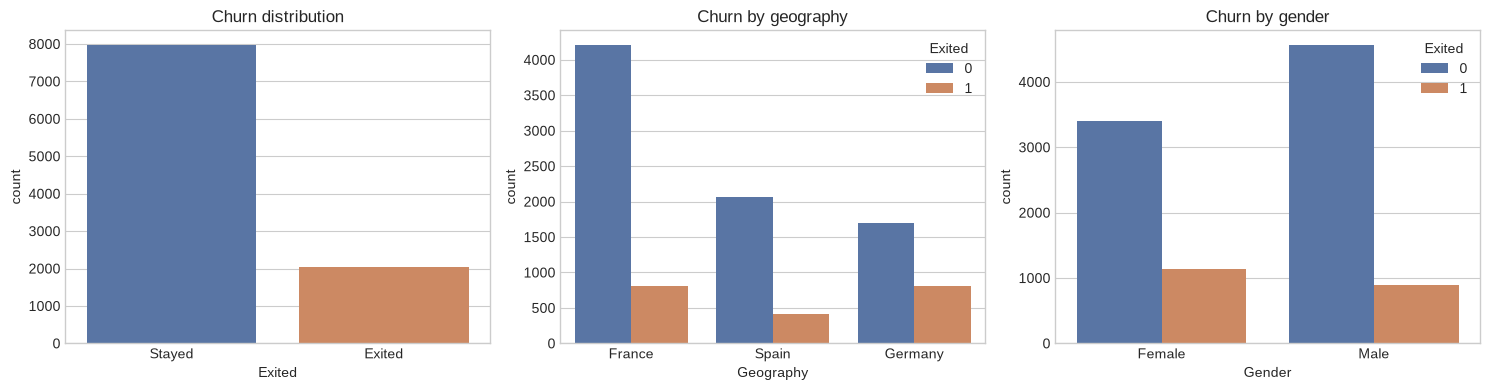

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="Exited", ax=axes[0], palette=["#4c72b0", "#dd8452"])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Stayed", "Exited"])
axes[0].set_title("Churn distribution")

sns.countplot(
    data=df, x="Geography", hue="Exited", ax=axes[1], palette=["#4c72b0", "#dd8452"]
)
axes[1].set_title("Churn by geography")

sns.countplot(
    data=df, x="Gender", hue="Exited", ax=axes[2], palette=["#4c72b0", "#dd8452"]
)
axes[2].set_title("Churn by gender")

plt.tight_layout()
plt.show()

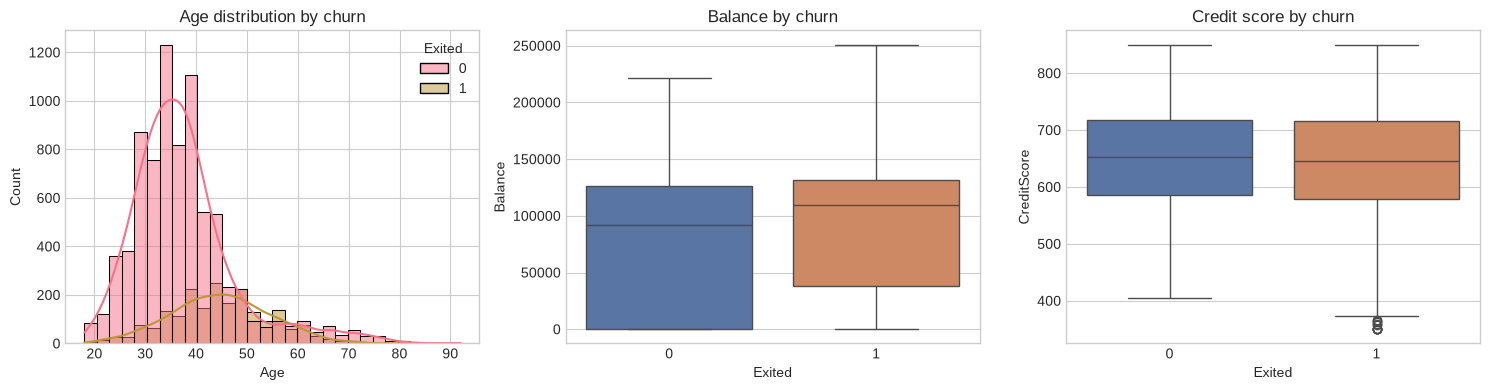

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data=df, x="Age", hue="Exited", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age distribution by churn")

sns.boxplot(data=df, x="Exited", y="Balance", ax=axes[1], palette=["#4c72b0", "#dd8452"])
axes[1].set_title("Balance by churn")

sns.boxplot(data=df, x="Exited", y="CreditScore", ax=axes[2], palette=["#4c72b0", "#dd8452"])
axes[2].set_title("Credit score by churn")

plt.tight_layout()
plt.show()

### 4.1 Pre-processing

1. Drop the three identifier columns; they cannot generalise to new customers.
2. One-hot encode `Geography` and `Gender` (drop the first category to avoid
   perfect multicollinearity).
3. Split into training and test sets using **stratification** so that both
   sets have the same churn rate.
4. Standardise the features using statistics from the training set only.

In [7]:
model_data = df.drop(columns=["RowNumber", "CustomerId", "Surname"]).copy()
y = model_data["Exited"]
X_raw = model_data.drop(columns=["Exited"])

# Split the raw data first so that X_test_raw keeps the original categorical
# columns for the interpretation table at the end.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

# One-hot encode after the split. Reindex the test set so that both matrices
# have exactly the same columns even if a category is absent from one split.
X_train_encoded = pd.get_dummies(
    X_train_raw, columns=["Geography", "Gender"], drop_first=True, dtype=int
)
X_test_encoded = pd.get_dummies(
    X_test_raw, columns=["Geography", "Gender"], drop_first=True, dtype=int
).reindex(columns=X_train_encoded.columns, fill_value=0)

feature_names = list(X_train_encoded.columns)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_encoded)
X_test = scaler.transform(X_test_encoded)

print("Features:", feature_names)
print("Training rows:", len(X_train))
print("Test rows    :", len(X_test))
print("Training churn rate:", f"{y_train.mean():.2%}")
print("Test churn rate    :", f"{y_test.mean():.2%}")

Features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
Training rows: 8000
Test rows    : 2000
Training churn rate: 20.38%
Test churn rate    : 20.35%


### 4.2 Baseline neural network

The baseline is deliberately simple: one hidden layer with 16 ReLU units and a
sigmoid output. This gives a reference point before improvements.

In [8]:
baseline_start = time.perf_counter()
baseline_model = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
)
baseline_model.fit(X_train, y_train)
baseline_time = time.perf_counter() - baseline_start

baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]
baseline_predictions = (baseline_probabilities >= 0.5).astype(int)

print(f"Baseline trained in {baseline_time:.2f} s")
print("Iterations:", baseline_model.n_iter_)
print("Final training loss:", round(baseline_model.loss_, 4))

Baseline trained in 2.60 s
Iterations: 191
Final training loss: 0.333


In [9]:
def evaluate_classifier(name, y_true, predictions, probabilities):
    """Return a row of classification metrics."""
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions),
        "recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
    }


baseline_metrics = pd.DataFrame(
    [evaluate_classifier("Baseline MLP (16)", y_test, baseline_predictions, baseline_probabilities)]
)
baseline_metrics

,model,accuracy,precision,recall,F1,ROC-AUC
0,Baseline MLP (16),0.8605,0.760163,0.459459,0.572741,0.86215


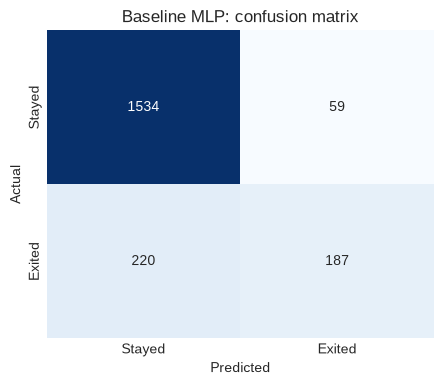

              precision    recall  f1-score   support

      Stayed       0.87      0.96      0.92      1593
      Exited       0.76      0.46      0.57       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.74      2000
weighted avg       0.85      0.86      0.85      2000



In [10]:
baseline_matrix = confusion_matrix(y_test, baseline_predictions)

plt.figure(figsize=(5, 4))
sns.heatmap(
    baseline_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Stayed", "Exited"],
    yticklabels=["Stayed", "Exited"],
)
plt.title("Baseline MLP: confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, baseline_predictions, target_names=["Stayed", "Exited"]))

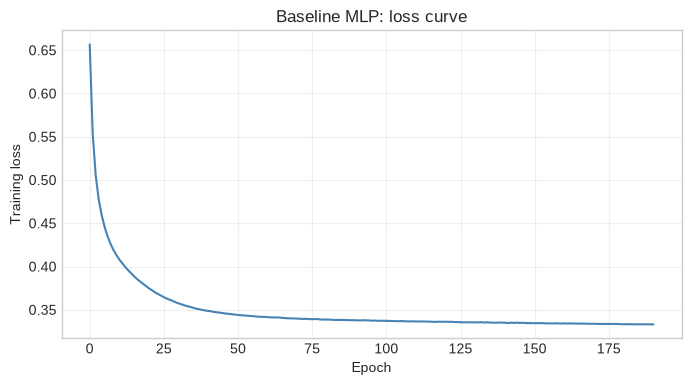

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(baseline_model.loss_curve_, color="steelblue")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Baseline MLP: loss curve")
plt.grid(alpha=0.3)
plt.show()

### 4.3 Identifying points of improvement

The baseline has a typical problem for imbalanced data: it predicts the
majority class very well but misses many churners. The confusion matrix and
recall show this. Improvements we can implement:

1. **Deeper architecture** — two hidden layers `(64, 32)` can learn
   interactions between age, balance, products and activity.
2. **Early stopping** — stop when validation loss stops improving, reducing
   overfitting.
3. **L2 regularisation** — a small `alpha` keeps the weights small.
4. **Class weighting** — give the churn class a weight of 2 so that missing a
   churner costs more than a false alarm.
5. **More iterations** — allow the optimiser enough epochs with early stopping.

All of these are combined in the improved model below.

In [12]:
# Class weights: class 0 -> 1.0, class 1 (churn) -> 2.0.
sample_weights = np.where(y_train == 1, 2.0, 1.0)

improved_start = time.perf_counter()
improved_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=15,
    random_state=42,
)
improved_model.fit(X_train, y_train, sample_weight=sample_weights)
improved_time = time.perf_counter() - improved_start

improved_probabilities = improved_model.predict_proba(X_test)[:, 1]
improved_predictions = (improved_probabilities >= 0.5).astype(int)

print(f"Improved MLP trained in {improved_time:.2f} s")
print("Iterations:", improved_model.n_iter_)
print("Final training loss:", round(improved_model.loss_, 4))

Improved MLP trained in 1.56 s
Iterations: 50
Final training loss: 0.3691


In [13]:
improved_metrics = pd.DataFrame(
    [evaluate_classifier("Improved MLP (64, 32) + weights", y_test, improved_predictions, improved_probabilities)]
)

comparison = pd.concat([baseline_metrics, improved_metrics], ignore_index=True)
comparison

,model,accuracy,precision,recall,F1,ROC-AUC
0,Baseline MLP (16),0.8605,0.760163,0.459459,0.572741,0.862150
1,"Improved MLP (64, 32) + weights",0.8455,0.616667,0.636364,0.626360,0.859177


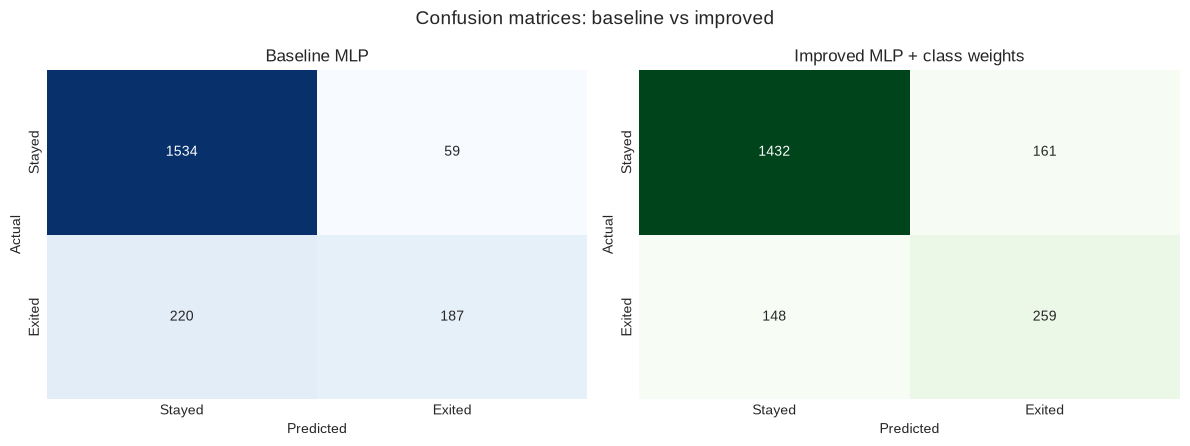

In [14]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, predictions, title in [
    (axes[0], baseline_predictions, "Baseline MLP"),
    (axes[1], improved_predictions, "Improved MLP + class weights"),
]:
    matrix = confusion_matrix(y_test, predictions)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Greens" if "Improved" in title else "Blues",
        cbar=False,
        xticklabels=["Stayed", "Exited"],
        yticklabels=["Stayed", "Exited"],
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.suptitle("Confusion matrices: baseline vs improved", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
print("Improved model classification report")
print(classification_report(y_test, improved_predictions, target_names=["Stayed", "Exited"]))

Improved model classification report
              precision    recall  f1-score   support

      Stayed       0.91      0.90      0.90      1593
      Exited       0.62      0.64      0.63       407

    accuracy                           0.85      2000
   macro avg       0.76      0.77      0.76      2000
weighted avg       0.85      0.85      0.85      2000



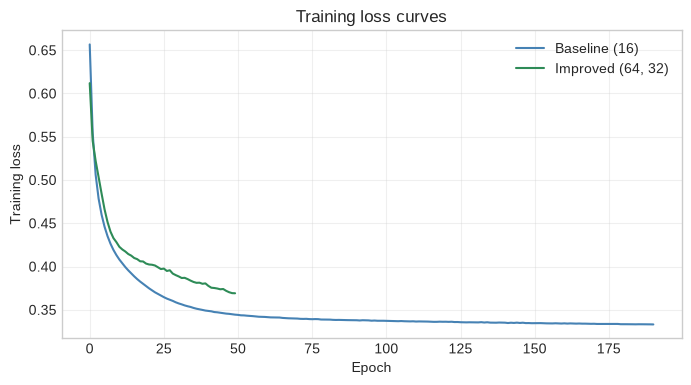

In [16]:
# Loss curves.
plt.figure(figsize=(8, 4))
plt.plot(baseline_model.loss_curve_, label="Baseline (16)", color="steelblue")
plt.plot(improved_model.loss_curve_, label="Improved (64, 32)", color="seagreen")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

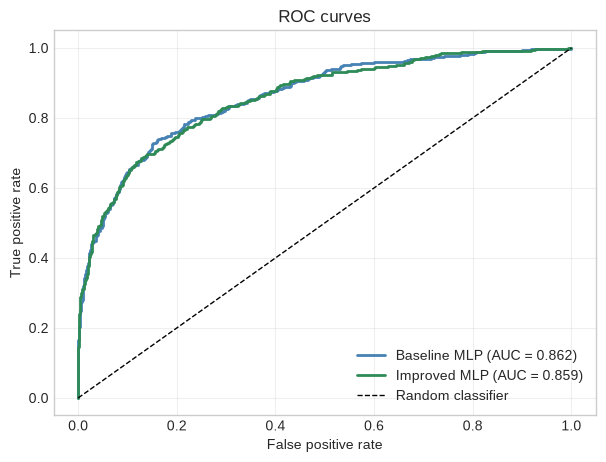

In [17]:
# ROC curves.
plt.figure(figsize=(7, 5))
for name, probabilities, colour in [
    ("Baseline MLP", baseline_probabilities, "steelblue"),
    ("Improved MLP", improved_probabilities, "seagreen"),
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", color=colour, linewidth=2)
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 4.4 Which features matter?

Neural networks are often treated as black boxes. **Permutation importance**
gives an interpretable summary: shuffle one feature and measure how much the
model's ROC-AUC drops. A large drop means the feature is important.

In [18]:
importance_start = time.perf_counter()
importance = permutation_importance(
    improved_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)
importance_time = time.perf_counter() - importance_start

importance_table = pd.DataFrame(
    {
        "feature": feature_names,
        "importance": importance.importances_mean,
        "std": importance.importances_std,
    }
).sort_values("importance", ascending=False)

print(f"Permutation importance computed in {importance_time:.2f} s")
importance_table

Permutation importance computed in 3.55 s


,feature,importance,std
1,Age,0.121787,0.008676
4,NumOfProducts,0.121613,0.005816
3,Balance,0.030430,0.006433
6,IsActiveMember,0.029545,0.003278
8,Geography_Germany,0.022090,0.002713
10,Gender_Male,0.006293,0.003348
9,Geography_Spain,0.003947,0.001740
2,Tenure,0.001421,0.001263
0,CreditScore,0.000877,0.001306
5,HasCrCard,0.000640,0.001210


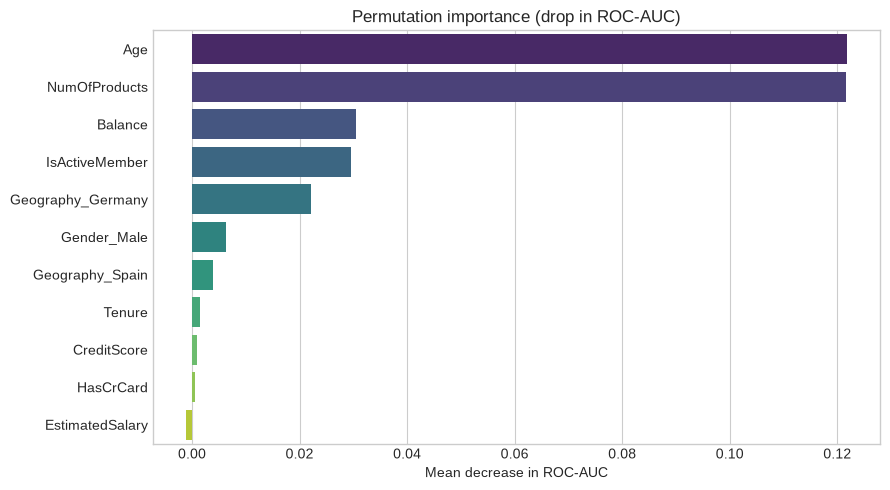

In [19]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_table,
    x="importance",
    y="feature",
    palette="viridis",
)
plt.title("Permutation importance (drop in ROC-AUC)")
plt.xlabel("Mean decrease in ROC-AUC")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 4.5 Individual customer predictions

The table shows a few test customers with the original (unscaled) feature
values. `P(exited)` is the network's probability; the prediction uses a 0.5
threshold.

In [20]:
test_view = X_test_raw.iloc[:10].copy()
test_view["actual"] = y_test.iloc[:10].values
test_view["P(exited)"] = improved_probabilities[:10].round(3)
test_view["prediction"] = improved_predictions[:10]
test_view["correct"] = test_view["actual"] == test_view["prediction"]
test_view[
    [
        "CreditScore",
        "Geography",
        "Gender",
        "Age",
        "Balance",
        "NumOfProducts",
        "IsActiveMember",
        "actual",
        "P(exited)",
        "prediction",
        "correct",
    ]
]

,CreditScore,Geography,Gender,Age,Balance,NumOfProducts,IsActiveMember,actual,P(exited),prediction,correct
5702,585,France,Male,36,0.00,2,0,0,0.029,0,True
3667,525,Germany,Male,33,131023.76,2,0,0,0.080,0,True
1617,557,Spain,Female,40,0.00,2,1,0,0.086,0,True
5673,639,Spain,Male,34,139393.19,2,0,0,0.315,0,True
4272,640,Spain,Female,34,77826.80,1,1,0,0.139,0,True
8270,559,Spain,Male,34,0.00,1,0,0,0.340,0,True
7079,595,Germany,Male,30,130682.11,2,1,0,0.034,0,True
5295,706,Germany,Female,29,185544.36,1,0,0,0.475,0,True
845,505,France,Male,49,80001.23,1,0,0,0.779,1,False
5311,714,France,Female,40,0.00,2,0,0,0.149,0,True


In [21]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - ML Practical 3 (Bank customer churn)")
print("=" * 78)
print(
    "The target is binary: Exited=1 means the customer left the bank. The\n"
    "dataset is imbalanced, so a model that predicts 'stayed' for everyone can\n"
    "look accurate while being useless for retention. The report focuses on\n"
    "recall, F1 and the confusion matrix, not only on accuracy."
)

print("\n1. DATASET AND CLASS BALANCE")
print("-" * 78)
exited_counts = df["Exited"].value_counts().sort_index()
print(f"Rows               : {len(df):,}")
print(f"Stayed (0)         : {int(exited_counts.get(0, 0)):,}")
print(f"Exited (1)         : {int(exited_counts.get(1, 0)):,}")
print(f"Churn rate         : {df['Exited'].mean():.2%}")
print(f"Training rows      : {len(X_train):,}")
print(f"Test rows          : {len(X_test):,}")
print(f"Missing values     : {int(df.isna().sum().sum())}")
print("Because only about one in five customers churned, accuracy has a high")
print("floor: predicting the majority class already gives roughly 80%. Recall")
print("and F1 for the churn class are the meaningful metrics.")

print("\n2. BASELINE VS IMPROVED MODEL")
print("-" * 78)
for _, row in comparison.iterrows():
    print(
        f"  {row['model']:34s}: acc={row['accuracy']:.4f}, "
        f"prec={row['precision']:.4f}, rec={row['recall']:.4f}, "
        f"F1={row['F1']:.4f}, AUC={row['ROC-AUC']:.4f}"
    )
base = comparison.iloc[0]
improved = comparison.iloc[1]
print(
    f"Recall change  : {base['recall']:.4f} -> {improved['recall']:.4f} "
    f"({improved['recall'] - base['recall']:+.4f})"
)
print(
    f"F1 change      : {base['F1']:.4f} -> {improved['F1']:.4f} "
    f"({improved['F1'] - base['F1']:+.4f})"
)
print(
    f"Accuracy change: {base['accuracy']:.4f} -> {improved['accuracy']:.4f} "
    f"({improved['accuracy'] - base['accuracy']:+.4f})"
)
print("Class weighting makes a missed churner more expensive during training.")
print("The improved model deliberately trades some precision and overall")
print("accuracy for higher recall, which is usually the right trade-off for a")
print("retention campaign: it is better to investigate a few extra customers")
print("than to miss someone who is about to leave.")

print("\n3. CONFUSION MATRICES")
print("-" * 78)
base_tn, base_fp, base_fn, base_tp = baseline_matrix.ravel()
improved_matrix = confusion_matrix(y_test, improved_predictions)
impr_tn, impr_fp, impr_fn, impr_tp = improved_matrix.ravel()
print("Baseline MLP (16 hidden units):")
print(f"  TN={base_tn}, FP={base_fp}, FN={base_fn}, TP={base_tp}")
print("Improved MLP (64, 32) with class weights:")
print(f"  TN={impr_tn}, FP={impr_fp}, FN={impr_fn}, TP={impr_tp}")
print(
    f"Change: TN {impr_tn - base_tn:+d}, FP {impr_fp - base_fp:+d}, "
    f"FN {impr_fn - base_fn:+d}, TP {impr_tp - base_tp:+d}"
)
print("FN is the number of churners the bank fails to identify; TP is the")
print("number it catches. The improved model should reduce FN, even if FP rises.")
print("A false positive means a retained customer receives an unnecessary offer;")
print("a false negative means a leaving customer receives no intervention.")

print("\n4. TRAINING BEHAVIOUR")
print("-" * 78)
print(
    f"Baseline: iterations={baseline_model.n_iter_}, "
    f"final loss={baseline_model.loss_:.4f}, time={baseline_time:.2f} s"
)
print(
    f"Improved: iterations={improved_model.n_iter_}, "
    f"final loss={improved_model.loss_:.4f}, time={improved_time:.2f} s"
)
print("The improved network is deeper and uses early stopping, L2 regularisation")
print("and class weights. Early stopping monitors a validation fraction of the")
print("training data and stops when it stops improving, which limits overfitting.")
print("A lower training loss is not automatically better; the test metrics and")
print("the loss curves together show whether the model generalises.")

print("\n5. WHICH FEATURES MATTER?")
print("-" * 78)
for _, row in importance_table.head(8).iterrows():
    print(
        f"  {row['feature']:20s}: mean AUC drop={row['importance']:.4f} "
        f"(std={row['std']:.4f})"
    )
print("Permutation importance shuffles one feature and measures how much ROC-AUC")
print("falls. A large drop means the model relies on that feature. Age, number")
print("of products, balance and active-member status are typically the strongest")
print("signals. This is model behaviour, not proof of causation.")

print("\n6. SAMPLE CUSTOMER PREDICTIONS")
print("-" * 78)
for _, row in test_view.head(6).iterrows():
    print(
        f"  actual={int(row['actual'])}, P(exited)={row['P(exited)']:.3f}, "
        f"prediction={int(row['prediction'])}, correct={bool(row['correct'])}, "
        f"age={row['Age']}, products={row['NumOfProducts']}, "
        f"active={row['IsActiveMember']}"
    )
print("The probability is more informative than the hard 0/1 label: a customer")
print("with P(exited)=0.70 is a much stronger retention target than one with")
print("P(exited)=0.51, even though both cross the default 0.5 threshold.")

print("\n7. TAKEAWAY")
print("-" * 78)
print("Accuracy is misleading for imbalanced churn data. Class weights increase")
print("recall for the minority class; the final threshold should be chosen from")
print("the business cost of false positives versus false negatives. A neural")
print("network is one option, but gradient-boosted trees often match or beat it")
print("on tabular data of this size.")

DETAILED OUTPUT EXPLANATION - ML Practical 3 (Bank customer churn)
The target is binary: Exited=1 means the customer left the bank. The
dataset is imbalanced, so a model that predicts 'stayed' for everyone can
look accurate while being useless for retention. The report focuses on
recall, F1 and the confusion matrix, not only on accuracy.

1. DATASET AND CLASS BALANCE
------------------------------------------------------------------------------
Rows               : 10,000
Stayed (0)         : 7,963
Exited (1)         : 2,037
Churn rate         : 20.37%
Training rows      : 8,000
Test rows          : 2,000
Missing values     : 0
Because only about one in five customers churned, accuracy has a high
floor: predicting the majority class already gives roughly 80%. Recall
and F1 for the churn class are the meaningful metrics.

2. BASELINE VS IMPROVED MODEL
------------------------------------------------------------------------------
  Baseline MLP (16)                 : acc=0.8605, prec=0.7

### Observations

1. The baseline network achieves high **accuracy** but low **recall** for
   churners. This is the accuracy paradox: predicting "stayed" for everyone
   would already be about 80% accurate, so accuracy alone is misleading.
2. Class weighting shifts the decision boundary towards the minority class.
   Recall for churners increases substantially, at the cost of some precision
   and overall accuracy.
3. The improved network has a better **F1** and a comparable **ROC-AUC**,
   which means it ranks customers by churn risk more usefully.
4. **Age**, **NumOfProducts**, **Balance** and **IsActiveMember** are usually
   among the most important features. This matches the exploratory plots:
   older and less active customers with more products are more likely to
   leave.
5. Early stopping prevents the deeper network from overfitting; the loss curve
   flattens after a small number of epochs.

### Limitations and improvements

- The dataset is synthetic/simplified; real churn depends on transactions,
  customer service contacts and competitor offers.
- A proper validation split (or cross-validation) should be used to tune the
  architecture, learning rate and class weights.
- Gradient boosting (XGBoost/LightGBM) is often stronger on tabular data.
- The decision threshold should be chosen from the business cost of a false
  positive versus a false negative.

## 5. Conclusion

We built a neural-network classifier for bank customer churn. After encoding
categorical variables and scaling the features, a simple one-hidden-layer MLP
provided a baseline. The confusion matrix showed that the baseline missed many
churners, so we implemented a deeper network with early stopping, L2
regularisation and class weights. The improved model increased recall and F1
for the churn class, giving a more useful model for retention campaigns.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is a neuron? | A weighted sum of inputs plus a bias, passed through an activation function. |
| Why is a non-linear activation needed? | Without it, stacked layers collapse into a single linear transformation. |
| What is back-propagation? | The chain-rule computation of gradients used to update the weights. |
| What does the sigmoid output represent? | The probability of the positive class. |
| Why one-hot encode Geography/Gender? | They are nominal categories with no natural order. |
| Why standardise features? | Neural networks converge faster and are less sensitive to feature scale. |
| Why is accuracy misleading for churn? | The majority class dominates; a model can be accurate while missing most churners. |
| How do class weights help? | They make errors on the minority class more expensive during training. |
| What is early stopping? | Stop training when validation performance stops improving, to avoid overfitting. |
| What is permutation importance? | The drop in a model metric when a feature's values are randomly shuffled. |